In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import lseg.data as ld
import matplotlib.pyplot as plt

In [2]:
EUR = ["EURAUD=", "EURCAD=", "EURCHF=" , "EURGBP=", "EURJPY=", "EUR="]
PERIOD = {"start": "2025-01-01", "end": "2025-12-31"}
TIMEFRAME = "30min"

def get_history(tickers):
    df = []
    for ticker in tickers:
        data = ld.get_history(ticker, start = PERIOD["start"], end = PERIOD["end"], interval = TIMEFRAME, fields=["BID", "ASK"])
        
        mid = (data["BID"] + data["ASK"]) / 2

        returns = mid.pct_change(fill_method=None).dropna()
        returns.name = ticker

        df.append(returns)

    return pd.concat(df, axis=1)


In [3]:
ld.open_session()

df = get_history(EUR)

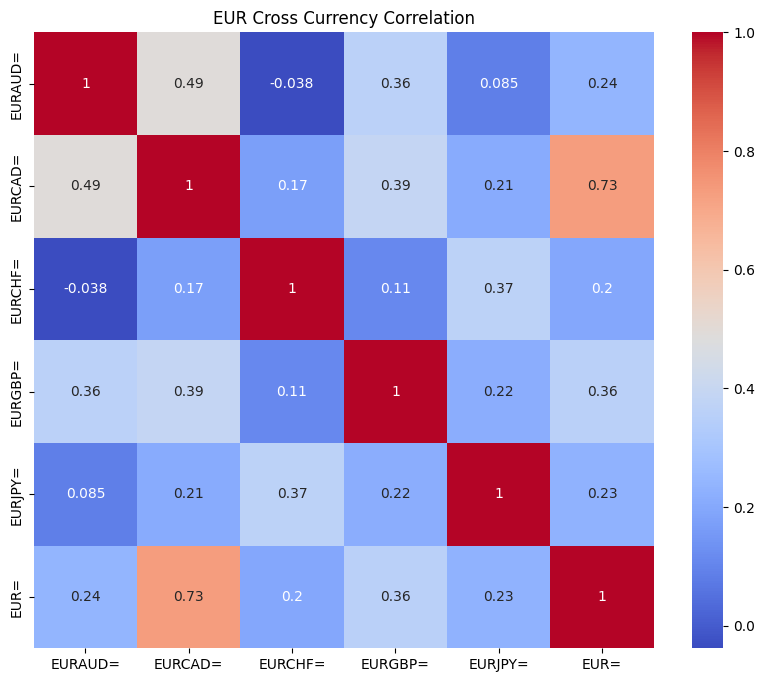

[Error 400] - {'error': 'invalid_grant'}


In [6]:
plt.figure(figsize=(10,8))
plt.title("EUR Cross Currency Correlation")
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()